In [1]:
import os, shutil, pathlib
import matplotlib.pyplot as plt
import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np

from PIL import Image

base_dir = pathlib.Path("./datasets/dinnerware_mix_background")

C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\requests\__init__.py:92: RequestsDependencyWarning: Unable to find acceptable character detection dependency (chardet or charset_normalizer).
  warnings.warn(


In [2]:
train_dataset = image_dataset_from_directory(
    base_dir / "train",
    label_mode='int',
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
validation_dataset = image_dataset_from_directory(
    base_dir / "validation",
    label_mode='int',
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)
test_dataset = image_dataset_from_directory(
    base_dir / "test",
    label_mode='int',
    image_size = (224, 224),
    batch_size = 32,
    seed=123,
)

Found 232 files belonging to 4 classes.
Found 49 files belonging to 4 classes.
Found 53 files belonging to 4 classes.


In [3]:
conv_base = keras.applications.vgg16.VGG16(
    weights="imagenet",
    include_top=False)
conv_base.trainable = False

conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, None, None, 3)  │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, None, None, 64) │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, None, None, 64) │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, None, None, 64) │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, None, None,     │        73,856 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, None, None,     │       147,584 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 128)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, None, None,     │       295,168 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, None, None,     │       590,080 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 256)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, None, None,     │     1,180,160 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, None, None,     │             0 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, None, None,     │     2,359,808 │
│                                 │ 512)                   │             

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 14,714,688 (56.13 MB)

In [4]:
data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.1),
        layers.RandomZoom(0.2)
    ]
)

inputs = keras.Input(shape=(224, 224, 3))
x = data_augmentation(inputs)
x = keras.applications.vgg16.preprocess_input(x)
x = conv_base(x)
x = layers.Flatten()(x)
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.5)(x)
outputs = layers.Dense(4, activation="softmax")(x)

model = keras.Model(inputs, outputs)

model.compile(optimizer="adam", loss="sparse_categorical_crossentropy",
              metrics=["accuracy"])

model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sequential          │ (None, 224, 224,  │          0 │ input_layer_1[0]… │
│ (Sequential)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item (GetItem)  │ (None, 224, 224)  │          0 │ sequential[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_1          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ get_item_2          │ (None, 224, 224)  │          0 │ sequential[0][0]  │
│ (GetItem)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stack (Stack)       │ (None, 224, 224,  │          0 │ get_item[0][0],   │
│                     │ 3)                │            │ get_item_1[0][0], │
│                     │                   │            │ get_item_2[0][0]  │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 224, 224,  │          0 │ stack[0][0]       │
│                     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ vgg16 (Functional)  │ (None, 7, 7, 512) │ 14,714,688 │ add[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten (Flatten)   │ (None, 25088)     │          0 │ vgg16[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 256)       │  6,422,784 │ flatten[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 256)       │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 4)         │      1,028 │ dropout[0][0]     │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 21,138,500 (80.64 MB)

 Trainable params: 6,423,812 (24.50 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [5]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="feature_extraction_with_data_augmentation.keras",
        save_best_only=True,
        monitor="val_loss")
]

history = model.fit(
    train_dataset,
    epochs=20,
    validation_data=validation_dataset,
    callbacks=callbacks)

C:\Users\miner\anaconda3\envs\keras\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


Epoch 1/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.5259 - loss: 18.8203 - val_accuracy: 0.7551 - val_loss: 6.2236
Epoch 2/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 51s 7s/step - accuracy: 0.8448 - loss: 2.5243 - val_accuracy: 0.8980 - val_loss: 2.2953
Epoch 3/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 51s 6s/step - accuracy: 0.8664 - loss: 2.5338 - val_accuracy: 0.8980 - val_loss: 1.6697
Epoch 4/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9267 - loss: 0.9267 - val_accuracy: 0.8571 - val_loss: 3.7591
Epoch 5/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 49s 6s/step - accuracy: 0.9483 - loss: 0.7034 - val_accuracy: 0.8776 - val_loss: 3.9312
Epoch 6/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9440 - loss: 0.5351 - val_accuracy: 0.8367 - val_loss: 1.9154
Epoch 7/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 75s 6s/step - accuracy: 0.9181 - loss: 1.4105 - val_accuracy: 0.9184 - val_loss: 1.8894
Epoch 8/20
8/8 ━━━━━━━━━━━━━━━━━━━━ 50s 6s/step - accuracy: 0.9655 - loss: 0.2378 - val_accuracy: 0.9184 - val_loss: 2.4982
Epoch 9

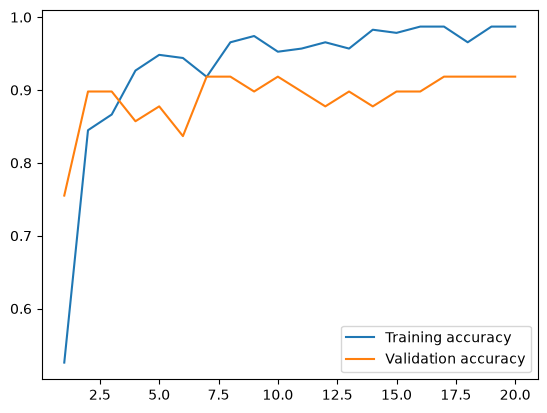

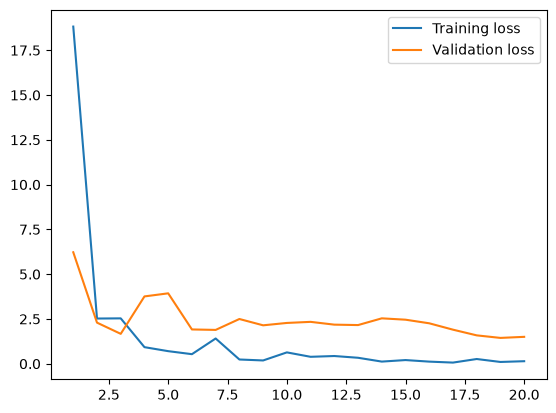

In [6]:
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
loss = history.history["loss"]
val_loss = history.history["val_loss"]
epochs = list(range(1, len(accuracy)+1))
plt.plot(epochs, accuracy, label="Training accuracy")
plt.plot(epochs, val_accuracy, label="Validation accuracy")
plt.legend()
plt.figure()
plt.plot(epochs, loss, label="Training loss")
plt.plot(epochs, val_loss, label="Validation loss")
plt.legend()
plt.show()

In [7]:
test_model = keras.models.load_model(
    "feature_extraction_with_data_augmentation.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 10s 4s/step - accuracy: 0.8679 - loss: 2.2085
Test accuracy: 0.867925


1/1 ━━━━━━━━━━━━━━━━━━━━ 6s 6s/step


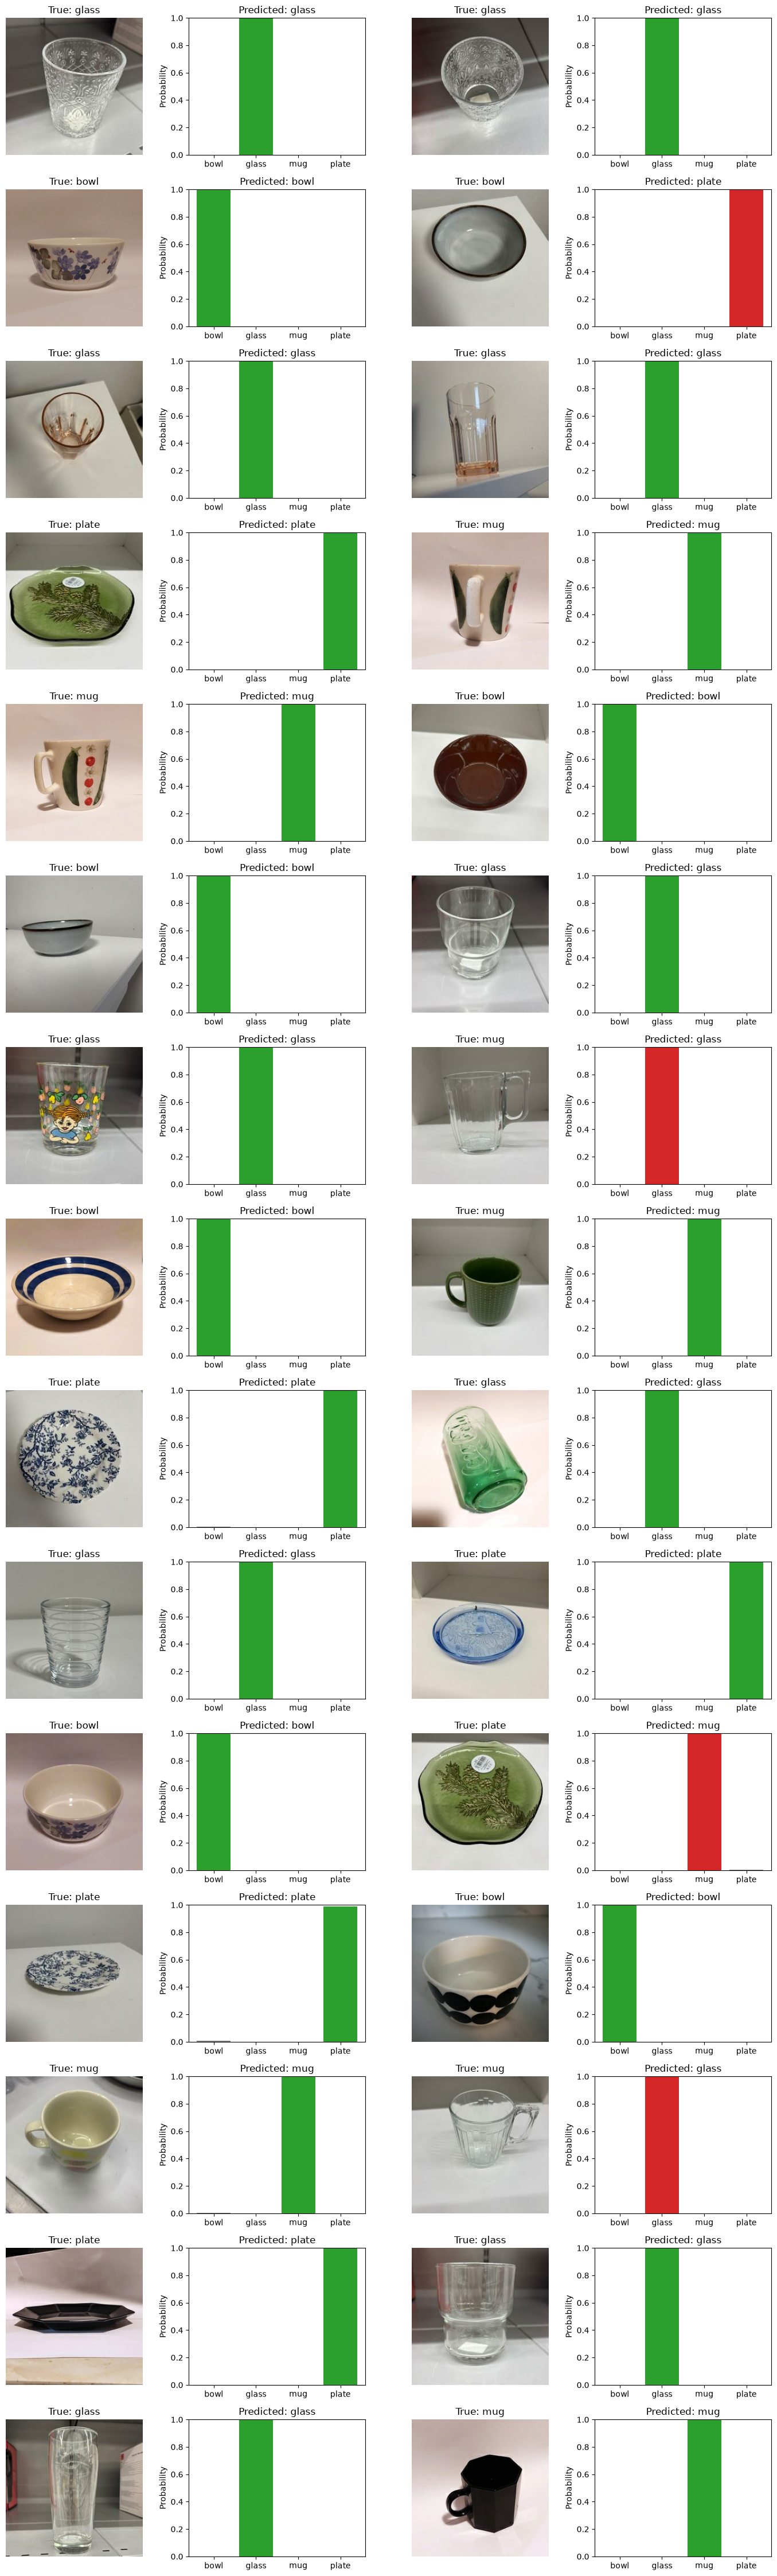

In [8]:
class_names = test_dataset.class_names

x, y = next(iter(test_dataset)) 
probs = test_model.predict(x)

start = 0
images_n = 30
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()

In [9]:
conv_base.trainable = True
for layer in conv_base.layers[:-4]:
    layer.trainable = False
    
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath="fine_tuning.keras",
        save_best_only=True,
        monitor="val_loss")
]

In [10]:
history = model.fit(
    train_dataset,
    epochs=30,
    validation_data=validation_dataset,
    callbacks=callbacks)

Epoch 1/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 59s 7s/step - accuracy: 0.9957 - loss: 0.0179 - val_accuracy: 0.8776 - val_loss: 1.7066
Epoch 2/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 54s 7s/step - accuracy: 0.9914 - loss: 0.0581 - val_accuracy: 0.8776 - val_loss: 2.5033
Epoch 3/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 54s 7s/step - accuracy: 0.9914 - loss: 0.0242 - val_accuracy: 0.8776 - val_loss: 2.1038
Epoch 4/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 60s 8s/step - accuracy: 0.9784 - loss: 0.0953 - val_accuracy: 0.8776 - val_loss: 1.7015
Epoch 5/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 57s 7s/step - accuracy: 1.0000 - loss: 0.0035 - val_accuracy: 0.8776 - val_loss: 1.6451
Epoch 6/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 54s 7s/step - accuracy: 0.9784 - loss: 0.0659 - val_accuracy: 0.8776 - val_loss: 1.6560
Epoch 7/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 56s 7s/step - accuracy: 0.9914 - loss: 0.0505 - val_accuracy: 0.9184 - val_loss: 1.5600
Epoch 8/30
8/8 ━━━━━━━━━━━━━━━━━━━━ 56s 7s/step - accuracy: 0.9871 - loss: 0.0433 - val_accuracy: 0.8980 - val_loss: 1.6149
Epoch 9/

In [11]:
test_model = keras.models.load_model("fine_tuning.keras")
test_loss, test_acc = test_model.evaluate(test_dataset)
print(f"Test accuracy: {test_acc:3f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 10s 4s/step - accuracy: 0.8868 - loss: 1.9280
Test accuracy: 0.886792


1/1 ━━━━━━━━━━━━━━━━━━━━ 3s 3s/step


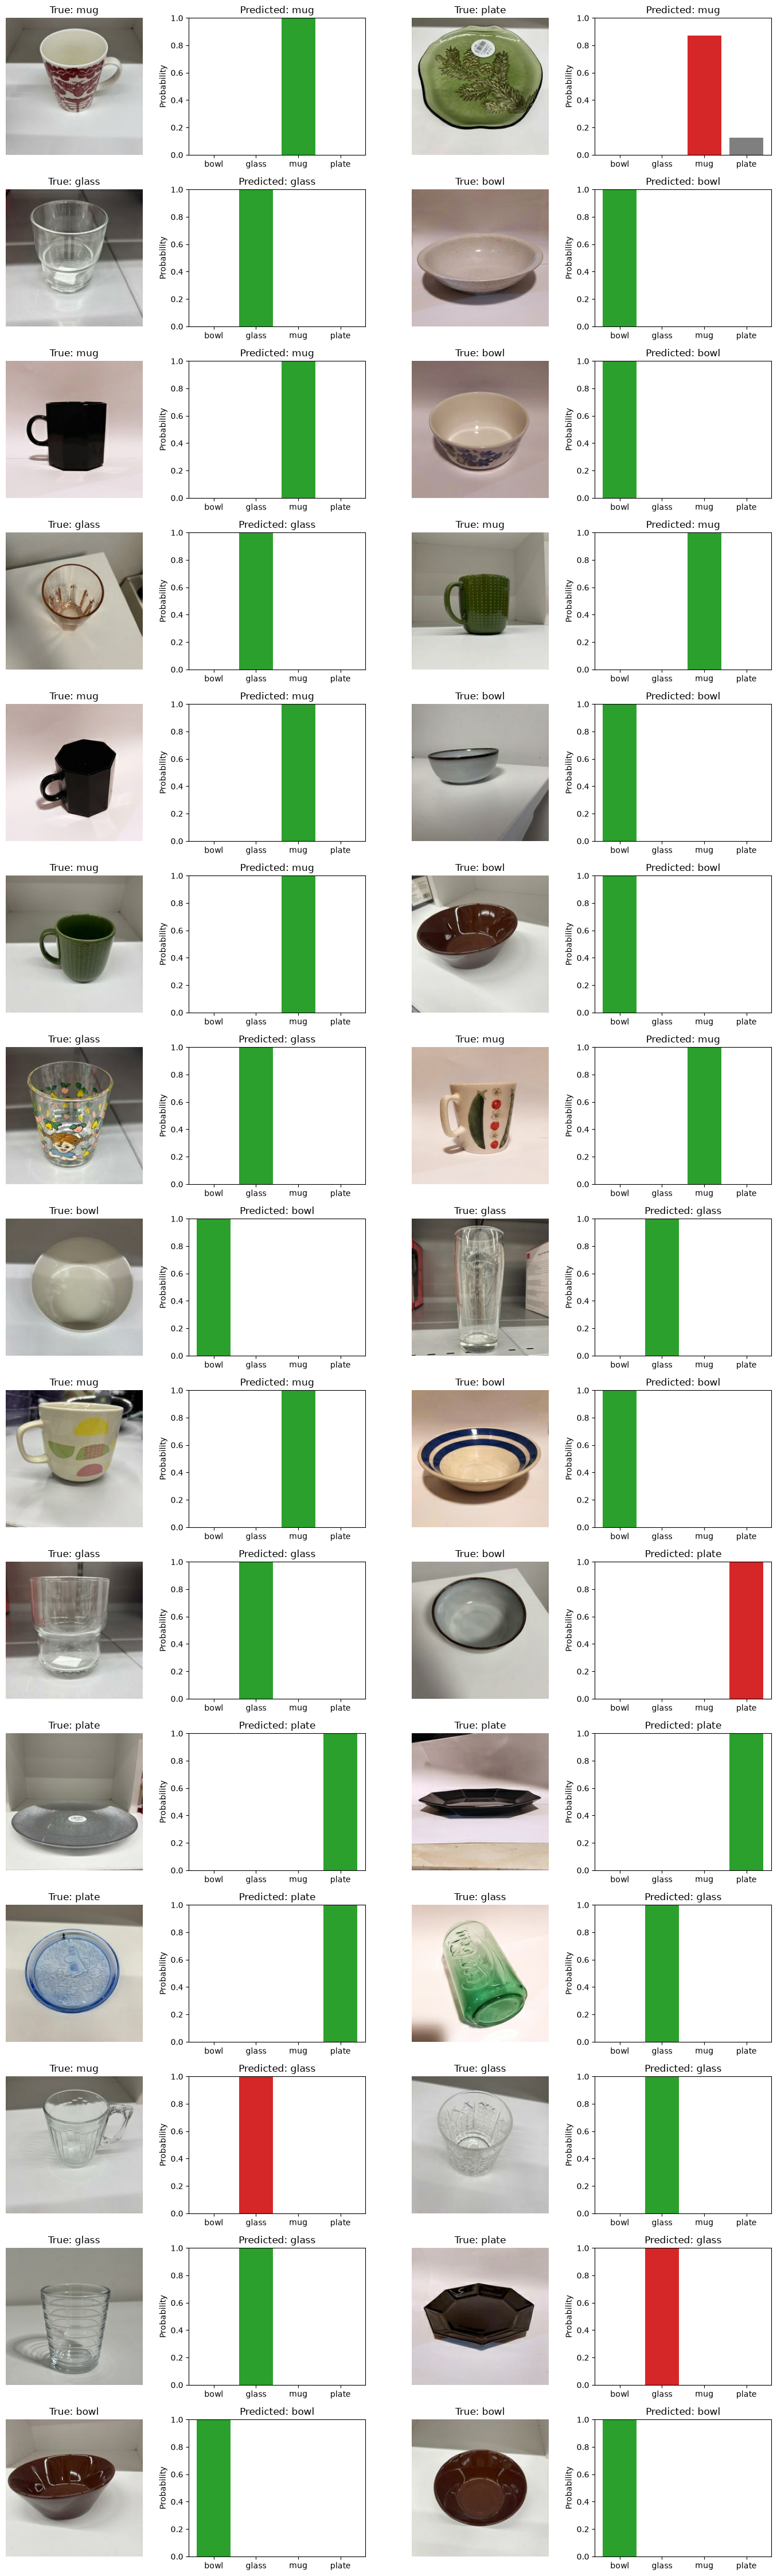

In [12]:
x, y = next(iter(test_dataset)) 
probs = test_model.predict(x)

start = 0
images_n = 30
rows = images_n // 2

plt.figure(figsize=(14, 3 * rows))

for k in range(images_n):
    i = start + k
    true_label = int(y[i])
    pred_label = int(np.argmax(probs[i]))
    correct = true_label == pred_label

    plt.subplot(rows, 4, 2 * k + 1)
    plt.imshow(x[i].numpy().astype("uint8"))
    plt.axis("off")
    plt.title(f"True: {class_names[true_label]}")

    plt.subplot(rows, 4, 2 * k + 2)
    colors = ["tab:gray"] * len(class_names)
    colors[pred_label] = "tab:green" if correct else "tab:red"
    plt.bar(class_names, probs[i], color=colors)
    plt.ylim(0, 1)
    plt.ylabel("Probability")
    plt.title(f"Predicted: {class_names[pred_label]}")

plt.tight_layout()
plt.show()